<div style="display: flex; background-color: RGB(255,114,0);" >
<h1 style="margin: auto; padding: 30px; ">ANALYSE DU STOCK ET DES VENTES DU SITE BOTTLENECK</h1>
</div>

# OBJECTIF DE CE NOTEBOOK

Bienvenue dans l'outil plébiscité par les analystes de données Jupyter.

Il s'agit d'un outil permettant de mixer et d'alterner code, texte et graphiques.

Cet outil est formidable pour plusieurs raisons:

+ Il permet de tester des lignes de codes au fur et à mesure de votre rédaction, de constater immédiatement le résultat d'une instruction, de la corriger si nécessaire.
+ Il permet aussi de rédiger du texte pour expliquer l'approche suivie ou les résultats d'une analyse et de le mettre en forme grâce à du code html ou plus simple avec **Markdown**
+ Il est possible d'ajouter des graphiques

Pour vous aider dans vos premiers pas à l'usage de Jupyter et de Python, nous avons rédigé ce notebook en vous indiquant les instructions à suivre.

Il vous suffit pour cela de saisir le code Python répondant à l'instruction donnée.

Vous verrez de temps à autre le code Python répondant à une instruction donnée mais cela est fait pour vous aider à comprendre la nature du travail qui vous est demandé.

Et gardez à l'esprit qu'il n'y a pas de solution unique pour résoudre un problème et qu'il y a autant de résolutions de problèmes que de développeurs ;)...



<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.1 - Importation des librairies</h3>
</div>

In [1]:
#Importation de la librairie Pandas
import pandas as pd

In [2]:
#Importation de la librairie plotly express
import plotly.express as px

In [3]:
#Trouver dans Google l'instruction permettant d'afficher toutes les colonnes d'un dataframe
#Saisir dans Google les mots clés "display all columns dataframe Pandas" par exemple.
#Dans les résultats de la recherche, privilégier les solutions provenant de Stack Overflow ou Medium
pd.set_option("display.max_columns", None)
# Permet d'afficher toutes les colonnes d'un DataFrame

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.2 - Chargements des fichiers</h3>
</div>

In [4]:
#Importation du fichier web.xlsx
df_web = pd.read_excel("web.xlsx")
#Importation du fichier erp.xlsx
df_erp = pd.read_excel("erp.xlsx")
#Importation du fichier liaison.xlsx
df_liaison = pd.read_excel("liaison.xlsx")

C:\Users\anton\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():
C:\Users\anton\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():
C:\Users\anton\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1 - Analyse exploratoire du fichier erp.xlsx</h3>
</div>

In [5]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(df_erp.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_erp.shape[1]))
# Le fichier ERP contient 825 lignes et 6 colonnes.

Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 6 colonne(s)


In [6]:
#Consulter le nombre de colonnes
#La nature des données dans chacune des colonnes
#Le nombre de valeurs présentes dans chacune des colonnes
df_erp.info()
# Les 6 colonnes contiennent 825 valeurs non nulles :
# aucune valeur manquante n'est détectée dans le fichier ERP.
# Les types semblent cohérents avec la nature des variables.

<class 'pandas.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      825 non-null    int64  
 1   onsale_web      825 non-null    int64  
 2   price           825 non-null    float64
 3   stock_quantity  825 non-null    int64  
 4   stock_status    825 non-null    str    
 5   purchase_price  825 non-null    float64
dtypes: float64(2), int64(3), str(1)
memory usage: 44.7 KB


In [7]:
#Afficher les 5 premières lignes de la table
df_erp.head(5)

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,outofstock,23.77


In [8]:
#Vérifier si il y a des lignes en doublon dans la colonne product_id
df_erp.duplicated("product_id").sum()
# Aucun doublon détecté sur product_id :
# chaque identifiant produit est unique dans le fichier ERP.

np.int64(0)

In [9]:
#Afficher les valeurs distinctes de la colonne stock_status
#À quelle(s) autre(s) colonne(s) sont-elles liées ?
df_erp["stock_status"].value_counts()
# Deux statuts sont présents : instock et outofstock.
# stock_status semble lié à stock_quantity
# Logiquement :
# stock_quantity > 0 devrait correspondre à instock
# stock_quantity = 0 devrait correspondre à outofstock

stock_status
instock       733
outofstock     92
Name: count, dtype: int64

In [10]:
#Création d'une colonne "stock_status_2"
#La valeur de cette deuxième colonne sera fonction de la valeur dans la colonne "stock_quantity"
#Si la valeur de la colonne "stock_quantity" est nulle, renseigner "outofstock" sinon mettre "instock"
df_erp.loc[
    df_erp["stock_quantity"] <= 0,
    "stock_status_2"
] = "outofstock"

df_erp.loc[
    df_erp["stock_quantity"] > 0,
    "stock_status_2"
] = "instock"
# Création d'un statut théorique à partir de stock_quantity :
# stock_quantity <= 0 = outofstock ; stock_quantity > 0 = instock.

In [11]:
#Vérifions que les 2 colonnes sont identiques:
#Les 2 colonnes sont strictement identiques si les valeurs de chaque ligne sont strictement identiques 2 à 2
#La comparaison de 2 colonnes peut se réaliser simplement avec l'instruction ci-dessous:
df_erp["stock_status"] == df_erp["stock_status_2"]

#Le résultat est l'affichage de True ou False pour chacune des lignes du dataset
#C'est un bon début, mais difficile à exploiter

# Comparaison ligne par ligne entre le statut d'origine et le statut calculé.
# True = cohérence entre les deux statuts ; False = incohérence.

0       True
1       True
2       True
3       True
4      False
       ...  
820     True
821     True
822     True
823     True
824     True
Length: 825, dtype: bool

In [12]:
#Mais il est possible de synthétiser ce résultat en effectuant la somme de cette colonne:
#True vaut 1 et False 0
#Nous devrions obtenir la somme de 824 qui correspond au nombre de lignes dans ce dataset
(df_erp["stock_status"] == df_erp["stock_status_2"]).sum()
# 823 lignes sur 825 ont un statut cohérent avec la quantité en stock.
# 2 lignes présentent donc une incohérence entre stock_status et stock_quantity.

np.int64(823)

In [13]:
#Si les colonnes ne sont absolument pas identiques ligne à ligne alors identifier la ligne en écart
##Dans ce cas je vous donne ce lien pour apprendre à réaliser des filtres dans Pandas:
##https://bitbucket.org/hrojas/learn-pandas/src/master/
##Lesson 3
df_erp.loc[
    df_erp["stock_status"] != df_erp["stock_status_2"]
]
# 2 lignes présentent une incohérence entre stock_status et stock_quantity.
# Elles doivent être analysées avant toute correction.

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
4,4039,1,46.0,3,outofstock,23.77,instock
398,4885,1,18.7,0,instock,9.66,outofstock


In [14]:
#Corriger la ou les données incohérentes

#Vérification en utilisant le même code que plus haut pour afficher les problèmes
# Correction des incohérences certaines entre stock_quantity et stock_status

# Le produit 4039 possède 3 unités en stock : son statut doit être "instock".
df_erp.loc[
    df_erp["product_id"] == 4039,
    "stock_status"
] = "instock"

# Le produit 4885 possède un stock nul : son statut doit être "outofstock".
df_erp.loc[
    df_erp["product_id"] == 4885,
    "stock_status"
] = "outofstock"

In [15]:
# Vérification des incohérences restantes après correction
df_erp.loc[
    df_erp["stock_status"] != df_erp["stock_status_2"]
]
# Après correction, aucune incohérence ne subsiste entre stock_status
# et le statut calculé à partir de stock_quantity.
# Les stocks négatifs (-10 et -1) restent néanmoins des anomalies
# de quantité à investiguer séparément.

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1 - Analyse exploratoire de chaque variable du fichier erp.xlsx</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.1 - Analyse de la variable PRIX</h3>
</div>

In [16]:
###############
## LES PRIX  ##
###############

#Vérification des prix: Y a t-il des prix non renseignés, négatifs ou nuls?
#Afficher le ou les prix non renseignés dans la colonne "price"
print("Nombres d'articles avec un prix non renseigné: {}".format(
    df_erp["price"].isnull().sum()
)) 
# Aucun prix manquant n'est détecté dans la colonne price.

#Afficher le prix minimum de la colonne "price"
print("Prix minimum : {}".format(
    df_erp["price"].min()
))
# Le prix minimum est négatif (-20.0) : il existe donc au moins une anomalie dans la colonne price.

#Afficher le prix maximum de la colonne "price"
print("Prix maximum : {}".format(
    df_erp["price"].max()
))
# Le prix maximum observé est de 225.0.

#Afficher les prix inférieurs à 0 (qu'est-ce qu'il faut en faire ?)
df_erp.loc[
    df_erp["price"] < 0
]
# 3 produits présentent un prix de vente négatif.
# Ces valeurs sont incohérentes et doivent être analysées avant correction.
df_erp["price"].describe()
# Les prix négatifs sont incohérents, mais leur valeur correcte ne peut pas
# être déterminée avec certitude à partir des données ERP disponibles.
# Une information métier complémentaire est nécessaire avant toute correction.

Nombres d'articles avec un prix non renseigné: 0
Prix minimum : -20.0
Prix maximum : 225.0


count    825.000000
mean      32.187697
std       26.712077
min      -20.000000
25%       14.500000
50%       24.300000
75%       42.000000
max      225.000000
Name: price, dtype: float64

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.2 - Analyse de la variable STOCK</h3>
</div>

In [17]:
#######################
### stock_quantity  ###
#######################

#Vérification de la colonne stock quantity
#Afficher la quantité minimum de la colonne "stock_quantity"
print("Quantité minimum en stock : {}".format(
    df_erp["stock_quantity"].min()
))
# La quantité minimum est négative (-10) : il existe donc au moins une anomalie dans stock_quantity.

#Afficher la quantité maximum de la colonne "stock_quantity"
print("Quantité maximum en stock : {}".format(
    df_erp["stock_quantity"].max()
))
# La quantité maximum observée est de 145 unités.

#Afficher les stocks inférieurs à 0 (qu'est-ce qu'il faut en faire ?)
df_erp.loc[
    df_erp["stock_quantity"] < 0
]

# Les stocks négatifs peuvent correspondre à plusieurs situations :
# commandes enregistrées malgré un stock nul, décalage de mise à jour ou erreur de saisie.
# Les données disponibles ne permettent pas de déterminer avec certitude leur origine.
# Ces valeurs sont donc conservées en l'état et devront être confirmées avec les règles métier.

Quantité minimum en stock : -10
Quantité maximum en stock : 145


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
449,4973,0,10.0,-10,outofstock,4.96,outofstock
573,5700,1,44.5,-1,outofstock,22.30,outofstock


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.3 - Analyse de la variable ONSALE_WEB</h3>
</div>

In [18]:
#Vérification de la colonne onsale_web et des valeurs qu'elle contient. Que signifient-elles?
df_erp["onsale_web"].value_counts()

# La colonne onsale_web contient uniquement les valeurs 0 et 1.
# Elle semble être un indicateur binaire :
# 1 = produit proposé à la vente sur le web ; 0 = produit non proposé sur le web.
# 716 produits sont proposés à la vente sur le web, contre 109 non proposés.

onsale_web
1    716
0    109
Name: count, dtype: int64

In [19]:
#Quelles sont les colonnes à conserver selon vous?

# Toutes les colonnes d'origine sont conservées.
# La colonne stock_status_2 est temporaire et peut être supprimée,
# car elle a uniquement servi à contrôler la cohérence de stock_status.

In [20]:
#Supprimer la colonne comportant le libellé "stock_status_2" car elle est redondante 
#avec la colonne "stock_status".
df_erp = df_erp.drop(columns=["stock_status_2"])

# La colonne stock_status_2 est supprimée du DataFrame df_erp.
# Le fichier source erp.xlsx d'origine n'est pas modifié.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.4 - Analyse de la variable prix d'achat</h3>
</div>

In [21]:
######################
##   prix d'achat   ##
######################

#Vérification de la colonne purchase_price : 
#Afficher le ou les prix non renseignés dans la colonne "purchase_price"
print("Nombre de prix d'achat non renseignés : {}".format(
    df_erp["purchase_price"].isnull().sum()
))
# Aucun prix d'achat manquant n'est détecté dans la colonne purchase_price.

#Afficher le prix minimum de la colonne "purchase_price"
print("Prix d'achat minimum : {}".format(
    df_erp["purchase_price"].min()
))
#Afficher le prix maximum de la colonne "purchase_price"
print("Prix d'achat maximum : {}".format(
    df_erp["purchase_price"].max()
))

# Aucun prix d'achat manquant n'est détecté.
# Les prix d'achat sont compris entre 2.74 et 137.81.
# Aucune anomalie évidente n'est observée à ce stade.

Nombre de prix d'achat non renseignés : 0
Prix d'achat minimum : 2.74
Prix d'achat maximum : 137.81


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2 - Analyse exploratoire du fichier web.xlsx</h3>
</div>
 

In [22]:
#Dimension du dataset
#Nombre d'observations

#Nombre de caractéristiques
print("Le tableau comporte {} observation(s) ou article(s)".format(df_web.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_web.shape[1]))
# Le fichier web contient 1513 observations et 29 colonnes.

Le tableau comporte 1513 observation(s) ou article(s)
Le tableau comporte 29 colonne(s)


In [23]:
#Consulter le nombre de colonnes
#La nature des données dans chacune des colonnes
#Le nombre de valeurs présentes dans chacune des colonnes
df_web.info()

<class 'pandas.DataFrame'>
RangeIndex: 1513 entries, 0 to 1512
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   sku                    1428 non-null   object        
 1   virtual                1513 non-null   int64         
 2   downloadable           1513 non-null   int64         
 3   rating_count           1513 non-null   int64         
 4   average_rating         1430 non-null   float64       
 5   total_sales            1430 non-null   float64       
 6   tax_status             716 non-null    str           
 7   tax_class              0 non-null      float64       
 8   post_author            1430 non-null   float64       
 9   post_date              1430 non-null   datetime64[us]
 10  post_date_gmt          1430 non-null   datetime64[us]
 11  post_content           0 non-null      float64       
 12  product_type           1429 non-null   str           
 13  post_title    

In [24]:
#Selon vous, quelles sont les colonnes à conserver ?
# Colonnes conservées pour l'analyse :
# - sku : identifiant produit côté web et future clé de jointure
# - total_sales : quantité vendue
# - product_type : type de produit
# - post_title : nom du produit
# - post_type : permet de distinguer les produits des pièces jointes
# - post_date : date de publication/création
# - post_modified : date de dernière modification


In [25]:
#Si vous avez défini des colonnes à supprimer, effectuer l'opération

# Suppression des colonnes non nécessaires pour l'analyse.
# Seules les colonnes utiles à l'identification des produits,
# aux ventes et à la compréhension de la structure du fichier web sont conservées.
df_web = df_web.drop(columns=[
    "virtual",
    "downloadable",
    "rating_count",
    "average_rating",
    "tax_status",
    "tax_class",
    "post_author",
    "post_date_gmt",
    "post_content",
    "post_excerpt",
    "post_status",
    "comment_status",
    "ping_status",
    "post_password",
    "post_name",
    "post_modified_gmt",
    "post_content_filtered",
    "post_parent",
    "guid",
    "menu_order",
    "post_mime_type",
    "comment_count"
])
# Le DataFrame df_web est maintenant réduit aux colonnes nécessaires pour la suite de l'analyse.
# Le fichier source web.xlsx d'origine n'est pas modifié.

In [26]:
# Vérification de la structure du DataFrame après suppression des colonnes inutiles.
print("Dimensions du fichier web après nettoyage : {}".format(
    df_web.shape
))

print("Colonnes conservées : {}".format(
    df_web.columns.tolist()
))

# Le fichier web contient toujours 1513 observations mais seulement 7 colonnes.
# Les 7 colonnes attendues ont bien été conservées après le nettoyage.

Dimensions du fichier web après nettoyage : (1513, 7)
Colonnes conservées : ['sku', 'total_sales', 'post_date', 'product_type', 'post_title', 'post_modified', 'post_type']


In [27]:
#Visualisation des valeurs de la colonne sku
df_web["sku"].unique()
#Quelles sont les valeurs qui ne semblent pas respecter la régle de codification?

# La majorité des SKU sont numériques.
# Certaines valeurs ont un format différent, notamment "13127-1"
# et "bon-cadeau-25-euros", ainsi que des valeurs manquantes (NaN).
# Ces cas doivent être examinés avant de conclure qu'il s'agit d'erreurs.

array([11862, 16057, 14692, 16295, 15328, 15471, 16515, 16246, nan, 13572,
       16513, 16585, 16269, 15526, 12869, 15575, 11586, 14338, 15425,
       16560, 15361, 13809, 11587, 15022, 14323, 16342, 16029, 15475,
       13754, 14680, 15875, 9636, 13849, 13662, 16564, 13557, 15429,
       14712, 15032, 15481, 15448, 16580, 15441, 804, 15300, 13958, 16071,
       15678, 13895, 15711, 12882, 16053, 13766, 16247, 12640, 15292,
       15476, 15670, 16189, 16038, 14864, 16044, 15324, 15531, 15953,
       15413, 15733, 14366, 15895, 15892, 16472, 15185, 16010, 15793,
       15849, 12315, 15741, 15934, 15148, 15781, 15659, 15106, 15490,
       14507, 14149, 16307, 13736, 14090, 16037, 15758, 14661, 12587,
       15337, 15489, 15201, 16305, 16131, 13435, 15747, 12203, 14509,
       14768, 16262, 14561, 16505, 15717, 16129, 13460, 15871, 15940,
       11602, 13127, 13520, 15480, 13032, 15436, 15269, 15910, 19821,
       16263, 15138, 15146, 15126, 15482, 16186, 13905, 16540, 15856,
       1567

In [28]:
#Si vous avez identifié des codes articles ne respectant pas la régle de codification, consultez-les
df_web.loc[
    df_web["sku"].isin([
        "13127-1",
        "bon-cadeau-25-euros"
    ])
]

# La majorité des SKU respectent une codification numérique.
# Les valeurs "13127-1" et "bon-cadeau-25-euros" correspondent à des produits existants,
# mais ne respectent pas la règle de codification numérique observée.
# Des valeurs manquantes (NaN) sont également présentes et doivent être analysées séparément.

,sku,total_sales,post_date,product_type,post_title,post_modified,post_type
272,13127-1,4.0,2020-06-09 15:42:04,Vin,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,2020-07-20 17:09:06,product
842,bon-cadeau-25-euros,7.0,2018-06-01 13:53:46,Autre,Bon cadeau de 25€,2018-06-01 14:13:57,attachment
1117,13127-1,4.0,2020-06-09 15:42:04,Vin,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,2020-07-20 17:09:06,attachment
1387,bon-cadeau-25-euros,7.0,2018-06-01 13:53:46,NaN,Bon cadeau de 25€,2018-06-01 14:13:57,product


In [29]:
#Identifier les lignes sans code article
df_web.loc[
    df_web["sku"].isna()
]
# 85 lignes ne possèdent pas de code article (sku).
# Les lignes visibles semblent majoritairement non renseignées,
# mais une analyse complémentaire est nécessaire avant toute suppression.

,sku,total_sales,post_date,product_type,post_title,post_modified,post_type
8,NaN,NaN,NaT,NaN,NaN,NaT,NaN
20,NaN,NaN,NaT,NaN,NaN,NaT,NaN
30,NaN,NaN,NaT,NaN,NaN,NaT,NaN
37,NaN,NaN,NaT,NaN,NaN,NaT,NaN
41,NaN,NaN,NaT,NaN,NaN,NaT,NaN
...,...,...,...,...,...,...,...
1384,NaN,NaN,NaT,NaN,NaN,NaT,NaN
1429,NaN,NaN,NaT,NaN,NaN,NaT,NaN
1432,NaN,NaN,NaT,NaN,NaN,NaT,NaN
1445,NaN,NaN,NaT,NaN,NaN,NaT,NaN


In [30]:
#Pour les codes articles identifiés, réaliser une analyse et définir l'action à entreprendre

# Les SKU "13127-1" et "bon-cadeau-25-euros" correspondent à des produits existants,
# mais leur format ne respecte pas la codification numérique majoritaire.
# Ils sont conservés pour l'instant afin de ne pas supprimer des produits valides.
# Leur codification devra être confirmée ou harmonisée selon les règles métier.

In [31]:
#La clé pour chaque ligne est-elle unique? autrement dit, y a-t-il des doublons?

# Vérification de l'unicité des SKU renseignés
print("Nombre de SKU dupliqués : {}".format(
    df_web.loc[df_web["sku"].notna(), "sku"].duplicated().sum()
))

# 714 occurrences de SKU sont identifiées comme doublons.
# Comme 1428 lignes possèdent un SKU pour 714 SKU distincts,
# chaque code article semble apparaître deux fois dans le fichier web.
# La nature de ces doublons doit être analysée avant toute suppression.

# Les valeurs manquantes (NaN) sont exclues de ce contrôle afin
# d'étudier uniquement l'unicité des codes articles réellement renseignés.

Nombre de SKU dupliqués : 714


In [32]:
#Les lignes sans code article semblent être toutes non renseignées
#Pour s'en assurer, réaliser les étapes suivantes:
#1 - Créer un dataframe avec uniquement les lignes sans code article
nouveau_df = df_web.loc[
    df_web["sku"].isna()
].copy()

#2 - Utiliser la fonction df.info() sur ce nouveau dataframe pour observer le nombre de valeurs renseignées dans chacune des colonnes
nouveau_df.info()

#3 - Que constatez-vous?

# Le DataFrame contient 85 lignes sans SKU.
# La colonne sku ne contient aucune valeur renseignée.
# Les autres colonnes ne contiennent que 2 valeurs non nulles chacune.
# La grande majorité des lignes sans code article semble donc vide.
# Les quelques lignes contenant encore des informations doivent être examinées
# avant de décider d'une éventuelle suppression.

<class 'pandas.DataFrame'>
Index: 85 entries, 8 to 1457
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   sku            0 non-null      object        
 1   total_sales    2 non-null      float64       
 2   post_date      2 non-null      datetime64[us]
 3   product_type   2 non-null      str           
 4   post_title     2 non-null      str           
 5   post_modified  2 non-null      datetime64[us]
 6   post_type      2 non-null      str           
dtypes: datetime64[us](2), float64(1), object(1), str(3)
memory usage: 5.5+ KB


In [33]:
# Vérification des lignes sans SKU contenant malgré tout d'autres informations
nouveau_df.loc[
    nouveau_df.drop(columns=["sku"]).notna().any(axis=1)
]

# Parmi les 85 lignes sans SKU, 83 semblent entièrement non renseignées.
# 2 lignes contiennent encore des informations produit et des valeurs total_sales négatives.
# L'absence de SKU empêche leur rapprochement avec les données ERP via la table de liaison.
# Aucun SKU ne peut être attribué avec certitude à partir des données disponibles.
# Ces lignes devront donc être écartées du rapprochement ou investiguées avec une source métier complémentaire.

,sku,total_sales,post_date,product_type,post_title,post_modified,post_type
1084,NaN,-56.0,2018-08-08 11:23:43,Vin,Pierre Jean Villa Condrieu Jardin Suspendu 2018,2019-11-02 13:24:01,product
1087,NaN,-17.0,2018-07-31 12:07:23,Vin,Pierre Jean Villa Côte Rôtie Fongeant 2017,2019-11-02 13:24:15,product


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3 - Analyse exploratoire du fichier liaison.xlsx</h3>
</div>

In [34]:
#Dimension du dataset
#Nombre d'observations
print("Le tableau comporte {} observation(s) ou article(s)".format(df_liaison.shape[0]))

#Nombre de caractéristiques
print("Le tableau comporte {} colonne(s)".format(df_liaison.shape[1]))

Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 2 colonne(s)


In [35]:
#Consulter le nombre de colonnes
#La nature des données dans chacune des colonnes
#Le nombre de valeurs présentes dans chacune des colonnes
df_liaison.info()

# Le fichier liaison contient 825 lignes et 2 colonnes.
# La colonne product_id est entièrement renseignée.
# La colonne id_web contient des valeurs manquantes.
# La vérification de l'unicité des deux identifiants doit être réalisée séparément.

<class 'pandas.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_web      734 non-null    object
 1   product_id  825 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 13.0+ KB


In [36]:
#Les valeurs de la colonne "product_id" sont-elles toutes uniques?
df_liaison["product_id"].duplicated().sum()

# Aucun doublon n'est détecté dans product_id.
# Les 825 identifiants produit sont donc uniques dans le fichier liaison.

np.int64(0)

In [37]:
#Les valeurs de la colonne "id_web" sont-elles toutes uniques?
df_liaison["id_web"].duplicated().sum()

# La commande détecte 90 doublons dans id_web.
# Cependant, la colonne contient aussi 91 valeurs manquantes.
# Ce résultat doit donc être interprété avec prudence.

np.int64(90)

In [38]:
df_liaison["id_web"].nunique()

# 734 id_web différents sont renseignés.
# Comme il y a également 734 valeurs non nulles, les id_web présents sont uniques.

734

In [39]:
#Avons-nous des articles sans correspondance?
df_liaison.loc[
    df_liaison["id_web"].isna()
]

# 91 articles ne possèdent pas de correspondance web.
# Leur id_web est manquant dans la table de liaison.
# Ces articles ne pourront donc pas être rapprochés directement
# avec les données du fichier web.

,id_web,product_id
19,NaN,4055
49,NaN,4090
50,NaN,4092
119,NaN,4195
131,NaN,4209
...,...,...
817,NaN,7196
818,NaN,7200
819,NaN,7201
820,NaN,7203


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Jonction des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.1 - Jonction du fichier df_erp et df_liaison</h3>
</div>

In [40]:
#Fusion des fichiers df_erp et df_liaison
df_merge = pd.merge(
    df_erp,
    df_liaison,
    on="product_id"
)
# Fusion des fichiers ERP et liaison à partir de la clé commune product_id

In [41]:
#Y a t-il des lignes ne "matchant" pas entre les 2 fichiers?

# Création d'une jointure externe pour conserver toutes les lignes
# des fichiers ERP et liaison et identifier les éventuelles non-correspondances.
controle_jointure = pd.merge(
    df_erp,
    df_liaison,
    on="product_id",
    how="outer",
    indicator=True
)

In [42]:
controle_jointure["_merge"].value_counts()

# Les 825 lignes trouvent une correspondance entre df_erp et df_liaison.
# Aucune ligne n'est présente uniquement dans l'ERP (left_only = 0).
# Aucune ligne n'est présente uniquement dans la table de liaison (right_only = 0).
# La jointure sur product_id est donc complète entre ces deux fichiers.

_merge
both          825
left_only       0
right_only      0
Name: count, dtype: int64

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.2 - Jonction du fichier df_merge et df_web</h3>
</div>

In [43]:
#Fusionner les datasets df_merge et df_web

# Première fusion entre les données ERP/liaison et les données web.
# Cette étape permet de vérifier le comportement de la jointure avant le nettoyage final.
# Les doublons liés aux lignes "attachment" et les clés manquantes seront traités ensuite.

df_merge_web = pd.merge(
    df_merge,
    df_web,
    left_on='id_web',
    right_on='sku',
    how='inner'
)

In [44]:
#Avons-nous des lignes sans correspondance?

# Création d'une jointure externe afin d'identifier les lignes sans correspondance.
# Ce premier contrôle montre toutefois que les valeurs manquantes présentes dans
# les deux fichiers peuvent être considérées comme des correspondances par Pandas.
# Un contrôle plus propre sera donc réalisé après retrait temporaire des clés manquantes.

controle_jointure_web = pd.merge(
    df_merge,
    df_web,
    left_on="id_web",
    right_on="sku",
    how="outer",
    indicator=True
)

In [45]:
# Création de versions temporaires sans clés de jointure manquantes
# afin d'éviter de fausses correspondances entre valeurs absentes.

df_merge_ok = df_merge.dropna(subset=["id_web"])
df_web_ok = df_web.dropna(subset=["sku"])

In [46]:
# Chaque SKU apparaît avec une ligne "product" et une ligne "attachment".
# Seules les lignes correspondant aux produits sont conservées.

df_web_produits = df_web_ok[df_web_ok["post_type"] == "product"]

In [47]:
# Fusion finale des données ERP/liaison avec les produits du site web.
# Les SKU atypiques sont conservés lorsqu'ils correspondent à des produits existants.

df_merge_web = pd.merge(
    df_merge_ok,
    df_web_produits,
    left_on="id_web",
    right_on="sku",
    how="inner"
)

In [48]:
df_merge_web.shape

# Le dataset final contient 714 produits et 14 colonnes.
# Ce résultat est cohérent avec les 714 SKU distincts identifiés dans le fichier web.

(714, 14)

In [49]:
####################################
# Contrôle de la jointure finale  #
####################################

# Effectuer une jointure externe de contrôle entre les données ERP / liaison
# et les produits du fichier Web afin d'identifier les correspondances
# et les éventuelles lignes non appariées.
controle_jointure_finale = pd.merge(
    df_merge_ok,
    df_web_produits,
    left_on="id_web",
    right_on="sku",
    how="outer",
    indicator=True
)

# Compter les lignes présentes dans les deux sources,
# uniquement dans ERP / liaison ou uniquement dans le Web.
print(controle_jointure_finale["_merge"].value_counts())

# Interprétation :
# "both" correspond aux produits présents dans les deux sources.
# "left_only" correspond aux produits ERP / liaison sans correspondance Web.
# "right_only" correspond aux produits Web sans correspondance ERP / liaison.
#
# Le dataset final df_merge_web conserve uniquement les correspondances fiables
# grâce à la jointure "inner".

_merge
both          714
left_only      20
right_only      0
Name: count, dtype: int64


In [50]:
# Interprétation du contrôle final :
# Sur les 734 produits ERP disposant d'un identifiant Web,
# 714 possèdent une correspondance fiable avec un produit du fichier Web.
#
# 20 produits possèdent un id_web mais aucune correspondance produit Web
# n'a été retrouvée après le nettoyage et le retrait des lignes "attachment".
#
# Aucun produit Web avec un SKU valide ne reste sans correspondance ERP / liaison.
#
# Les 91 produits ERP sans id_web avaient déjà été exclus de ce contrôle.
#
# On retrouve donc bien les 825 produits ERP :
# 714 produits appariés + 20 non appariés + 91 sans id_web = 825.
#
# Le dataset final conserve uniquement les 714 correspondances fiables.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse univariée des prix</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.1 - Exploration par la visualisation de données</h3>
</div>

<Axes: >

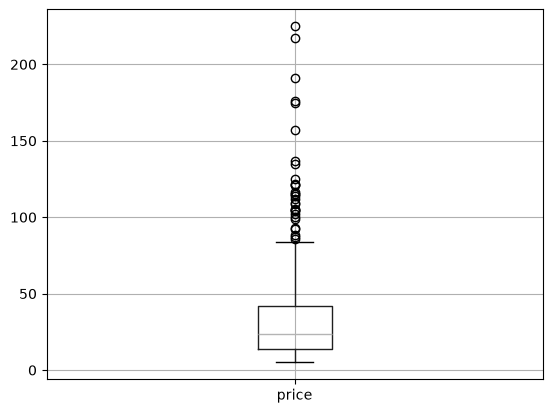

In [51]:
#Création d'une boîte à moustache de la répartition des prix grâce à Pandas
df_merge_web.boxplot(column="price")

# La majorité des prix est concentrée dans la partie basse du graphique.
# Plusieurs valeurs élevées apparaissent au-dessus de la moustache supérieure.
# Elles sont considérées comme des valeurs atypiques potentielles à analyser.

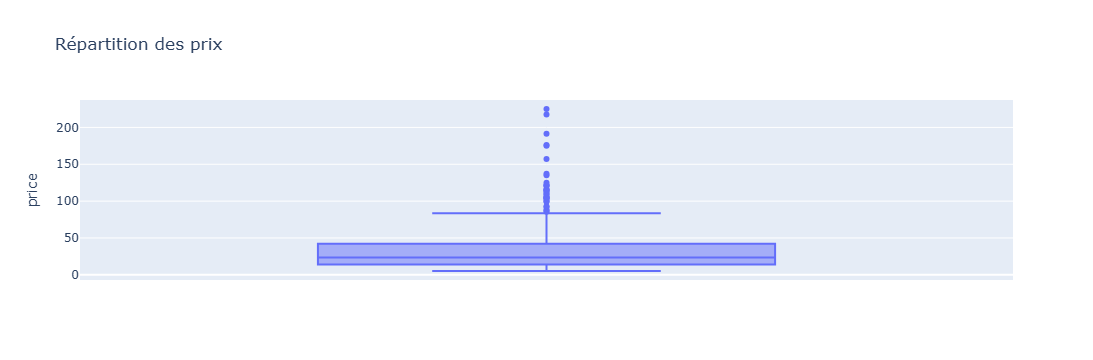

In [52]:
#Autre méthode avec plotly express
fig = px.box(
    df_merge_web,
    y="price",
    title="Répartition des prix"
)

fig.show()

# Le graphique confirme la présence de plusieurs prix élevés considérés
# comme des valeurs atypiques potentielles.
# Ces valeurs seront analysées avec des méthodes statistiques dans la suite.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2 - Exploration par l'utilisation de méthodes statistiques</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.1 - Identification par le Z-index</h3>
</div>

In [53]:
#Calculer la moyenne du prix
moyenne_prix = df_merge_web["price"].mean()
print("Moyenne des prix :", round(moyenne_prix, 2), "€")
# La moyenne permet de connaître le prix moyen des produits du catalogue.

#Calculer l'écart-type du prix
ecart_type_prix = df_merge_web["price"].std()
print("Écart-type des prix :", round(ecart_type_prix, 2), "€")
# L'écart-type permet de mesurer à quel point les prix sont éloignés de la moyenne.

#Calculer le Z-score
df_merge_web["z_score"] = (
    df_merge_web["price"] - moyenne_prix
) / ecart_type_prix
# Le Z-score permet de mesurer à combien d'écarts-types chaque prix se trouve de la moyenne.
# Une nouvelle colonne "z_score" est créée pour stocker le résultat pour chaque produit.

# Affichage des 5 premières lignes pour vérifier le calcul du Z-score.
print(df_merge_web[["price", "z_score"]].head())

Moyenne des prix : 32.33 €
Écart-type des prix : 27.6 €
   price   z_score
0   24.2 -0.294738
1   34.3  0.071253
2   20.8 -0.417943
3   14.1 -0.660729
4   46.0  0.495222


In [54]:
#Quel est le seuil prix dont le z-score est supérieur à 3?
df_merge_web.loc[df_merge_web["z_score"] > 3]

# Affichage des produits dont le Z-score est supérieur à 3.
# Ces produits ont un prix particulièrement éloigné de la moyenne
# et peuvent donc être considérés comme des valeurs atypiques potentielles.

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,sku,total_sales,post_date,product_type,post_title,post_modified,post_type,z_score
199,4352,1,225.0,0,outofstock,137.81,15940,15940,11.0,2018-03-02 10:30:04,Champagne,Champagne Egly-Ouriet Grand Cru Millésimé 2008,2020-03-07 11:18:45,product,6.981591
218,4402,1,176.0,11,instock,78.25,3510,3510,3.0,2018-03-22 11:21:05,Cognac,Cognac Frapin VIP XO,2020-08-22 11:35:03,product,5.205993
221,4406,1,157.0,12,instock,69.08,7819,7819,4.0,2018-03-22 11:42:48,Cognac,Cognac Frapin Château de Fontpinot 1989 20 Ans...,2020-03-14 16:05:04,product,4.517496
381,4904,1,137.0,9,instock,67.95,14220,14220,3.0,2018-05-15 10:23:41,Vin,Domaine Des Croix Corton Charlemagne Grand Cru...,2020-05-19 17:15:02,product,3.792762
426,5001,1,217.5,18,instock,116.87,14581,14581,2.0,2018-07-17 09:45:39,Vin,David Duband Charmes-Chambertin Grand Cru 2014,2020-05-16 09:00:05,product,6.709816
511,5612,1,124.8,19,instock,66.41,14915,14915,1.0,2019-01-15 15:30:49,Vin,Domaine Weinbach Gewurztraminer Grand Cru Furs...,2019-01-23 09:33:57,product,3.350674
553,5767,1,175.0,12,instock,90.42,15185,15185,4.0,2019-03-13 14:43:22,Vin,Camille Giroud Clos de Vougeot 2016,2020-06-11 15:25:04,product,5.169756
587,5892,1,191.3,98,instock,116.06,14983,14983,6.0,2019-03-28 10:21:36,Champagne,Coteaux Champenois Egly-Ouriet Ambonnay Rouge ...,2020-04-01 09:30:09,product,5.760415
603,5917,1,122.0,12,instock,54.24,14775,14775,3.0,2019-04-04 16:49:37,Whisky,Wemyss Malts Single Cask Scotch Whisky Choc 'n...,2020-03-11 09:30:09,product,3.249211
642,6126,1,135.0,138,instock,80.33,14923,14923,5.0,2019-06-28 17:22:27,Champagne,Champagne Gosset Célébris Vintage 2007,2020-08-27 11:45:02,product,3.720288


In [55]:
# Recherche du prix minimum parmi les produits ayant un Z-score supérieur à 3.
# Ce prix correspond au premier seuil à partir duquel un produit est considéré
# comme particulièrement éloigné de la moyenne selon cette méthode.
df_merge_web.loc[df_merge_web["z_score"] > 3, "price"].min()

# Le seuil de prix obtenu est de 116,40 €.
# Les produits dont le Z-score est supérieur à 3 ont un prix
# particulièrement éloigné de la moyenne.

np.float64(116.4)

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.2 - Identification par l'intervalle interquartile</h3>
</div>

In [56]:
#Utilisation de la fonction "describe" de Pandas pour l'étude des mesures de dispersion

# La fonction describe permet d'obtenir plusieurs statistiques sur les prix :
# moyenne, écart-type, minimum, maximum, médiane et quartiles.
# Les valeurs Q1 (25 %) et Q3 (75 %) seront utilisées pour calculer l'IQR.

mesure_dispersion = df_merge_web["price"].describe()

print(mesure_dispersion)

count    714.000000
mean      32.333683
std       27.596332
min        5.200000
25%       14.062500
50%       23.450000
75%       42.075000
max      225.000000
Name: price, dtype: float64


In [57]:
#Définir un seuil pour les articles "outliers" en prix

# Q1 correspond au premier quartile (25 %) et Q3 au troisième quartile (75 %).
# L'IQR correspond à l'écart entre Q3 et Q1.
q1 = df_merge_web["price"].quantile(0.25)
q3 = df_merge_web["price"].quantile(0.75)
iqr = q3 - q1

print("Q1 :", round(q1, 2), "€")
print("Q3 :", round(q3, 2), "€")
print("IQR :", round(iqr, 2), "€")

# Calcul des seuils bas et haut permettant d'identifier les valeurs atypiques.
seuil_bas = q1 - 1.5 * iqr
seuil_haut = q3 + 1.5 * iqr

print("Seuil bas :", round(seuil_bas, 2), "€")
print("Seuil haut :", round(seuil_haut, 2), "€")
# Les prix supérieurs au seuil haut de 84,09 € seront considérés
# comme des valeurs atypiques selon la méthode de l'IQR.

Q1 : 14.06 €
Q3 : 42.08 €
IQR : 28.01 €
Seuil bas : -27.96 €
Seuil haut : 84.09 €


In [58]:
#Définir le nombre d'articles et la proportion de l'ensemble du catalogue "outliers"

# Comptage des produits dont le prix dépasse le seuil haut défini précédemment.
nombre_outliers = df_merge_web.loc[
    df_merge_web["price"] > seuil_haut
].shape[0]

# Calcul de la proportion de ces produits dans l'ensemble du catalogue.
proportion = (nombre_outliers / len(df_merge_web)) * 100

print("Nombre d'outliers :", nombre_outliers)
print("Proportion d'outliers :", round(proportion, 2), "%")

# 31 produits sont identifiés comme des outliers selon la méthode de l'IQR.
# Ils représentent environ 4,34 % des 714 produits du catalogue.

Nombre d'outliers : 31
Proportion d'outliers : 4.34 %


In [59]:
#Selon vous, ces outliers sont-ils justifiés ? Comment le démontrer si cela est possible ?

# Affichage des produits identifiés comme outliers avec leur nom,
# leur type de produit et leur prix afin de vérifier leur cohérence.
df_merge_web.loc[
    df_merge_web["price"] > seuil_haut,
    ["post_title", "product_type", "price"]
]

# Les outliers correspondent principalement à des produits haut de gamme :
# grands crus, champagnes, cognacs ou whiskys.
# Leurs prix élevés semblent donc cohérents avec la nature des produits
# et ne constituent pas forcément des erreurs de prix.

,post_title,product_type,price
63,Zind-Humbrecht Riesling Grand Cru Rangen De Th...,Vin,100.0
65,Zind-Humbrecht Pinot Gris Grand Cru Rangen De ...,Vin,88.4
199,Champagne Egly-Ouriet Grand Cru Millésimé 2008,Champagne,225.0
205,Champagne Larmandier-Bernier Grand Cru Les Che...,Champagne,85.6
218,Cognac Frapin VIP XO,Cognac,176.0
219,Cognac Frapin Château de Fontpinot XO,Cognac,108.5
221,Cognac Frapin Château de Fontpinot 1989 20 Ans...,Cognac,157.0
222,Cognac Frapin Cigar Blend,Cognac,104.0
227,Château de Meursault Puligny-Montrachet 1er Cr...,Vin,109.6
380,Domaine Des Croix Corton Grand Cru Les Grèves ...,Vin,102.3


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Analyse univariée du CA, des quantités vendues, des stocks et de la marge ainsi qu'une analyse multivariée  </h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.1 - Analyse des ventes en CA</h3>
</div>

In [60]:
##############################
# Calculer le CA du site web #
##############################

#Créer une colonne calculant le CA par article
# Création d'une colonne calculant le chiffre d'affaires généré par chaque article.
# Le CA par article correspond au prix de vente multiplié par le nombre de ventes.
df_merge_web["ca_par_article"] = (
    df_merge_web["price"] * df_merge_web["total_sales"]
)
#Calculer la somme de la colonne "ca_par_article"
# Calcul du chiffre d'affaires total du site web en additionnant le CA de tous les articles.
ca_total = df_merge_web["ca_par_article"].sum()
print("Chiffre d'affaires total du site web :", round(ca_total, 2), "€")

#Ce résultat correspond au chiffre d'affaire du site web
# La somme de la colonne "ca_par_article" correspond au chiffre d'affaires total du site web.
# Le chiffre d'affaires total obtenu est de 143 680,10 €.

Chiffre d'affaires total du site web : 143680.1 €


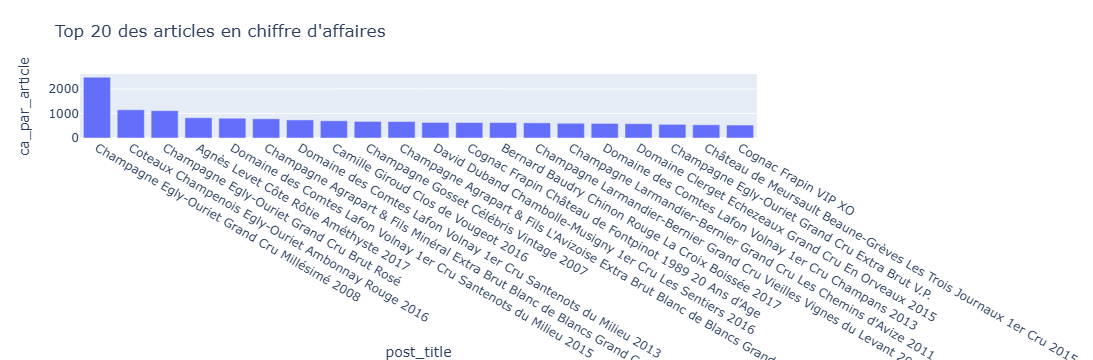

In [61]:
###############################
# Palmarès des articles en CA #
###############################

#Effectuer le tri dans l'ordre décroissant du CA du dataset df_merge
# Tri des produits selon leur chiffre d'affaires, du plus élevé au plus faible.
df_ca = df_merge_web.sort_values(
    by="ca_par_article",
    ascending=False
)

#Réinitialiser l'index du dataset par un reset_index
# Réinitialisation de l'index après le tri afin d'obtenir un classement de 0 à 713.
df_ca = df_ca.reset_index(drop=True)

#Afficher les 20 premiers articles en CA
# Affichage des 20 produits générant le plus de chiffre d'affaires.
df_ca.head(20)

#Graphique en barre des 20 premiers articles avec plotly express
fig = px.bar(
    df_ca.head(20),
    x="post_title",
    y="ca_par_article",
    title="Top 20 des articles en chiffre d'affaires"
)

fig.show()

# Création d'un graphique en barres pour visualiser les 20 meilleurs produits en CA.

In [62]:
# Le graphique permet d'identifier rapidement les produits qui contribuent
# le plus au chiffre d'affaires du site.

In [63]:
#############################
# Calculer le 20 / 80 en CA #
#############################

#Créer une colonne calculant la part du CA de la ligne dans le dataset
# Calcul de la part du chiffre d'affaires générée par chaque produit
# par rapport au chiffre d'affaires total du site.

df_ca["part_ca"] = (
    df_ca["ca_par_article"] / ca_total
)
# Addition progressive des parts de CA afin de connaître
# la part cumulée au fur et à mesure du classement des produits.

#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée
df_ca["cumul_ca"] = df_ca["part_ca"].cumsum()

#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% du CA
# Définition du seuil correspondant à 80 % du chiffre d'affaires.

seuil = 0.80

nombre_articles_ca = (
    df_ca["cumul_ca"] <= seuil
).sum()

# Comptage du nombre de produits nécessaires pour représenter
# environ 80 % du chiffre d'affaires total.

print("Nombre d'articles représentant 80 % du CA :", nombre_articles_ca)

# Calcul de la proportion que représente ce groupe
# par rapport à l'ensemble du catalogue.

#Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web
proportion_ca = (
    nombre_articles_ca / len(df_ca)
) * 100

print(
    "Proportion du catalogue représentant 80 % du CA :",
    round(proportion_ca, 2),
    "%"
)

# 434 produits représentent environ 80 % du chiffre d'affaires.
# Ils correspondent à environ 60,78 % du catalogue.
# La répartition du CA ne suit donc pas ici une règle stricte de 20/80.

Nombre d'articles représentant 80 % du CA : 434
Proportion du catalogue représentant 80 % du CA : 60.78 %


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.2 - Analyse des ventes en quantité</h3>
</div>

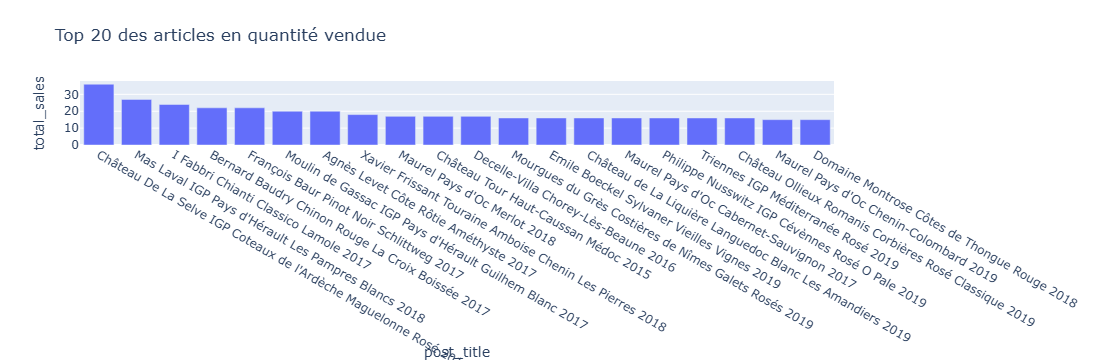

In [64]:
#####################################
# Palmarès des articles en quantité #
#####################################

# Effectuer le tri dans l'ordre décroissant de quantités vendues du dataset df_merge

# Tri des produits selon le nombre d'unités vendues,
# du produit le plus vendu au moins vendu.
df_quantites = df_merge_web.sort_values(
    by="total_sales",
    ascending=False
)
# Réinitialiser l'index du dataset par un reset_index

# Réinitialisation de l'index après le tri afin d'obtenir
# un classement plus simple à lire.
df_quantites = df_quantites.reset_index(drop=True)

# Afficher les 20 premiers articles en quantité
# Affichage des 20 produits ayant enregistré le plus de ventes.
df_quantites.head(20)

# Graphique en barre des 20 premiers articles avec plotly express
# Création d'un graphique en barres pour visualiser
# les 20 produits les plus vendus en quantité.
fig = px.bar(
    df_quantites.head(20),
    x="post_title",
    y="total_sales",
    title="Top 20 des articles en quantité vendue"
)

fig.show()

# Le graphique permet d'identifier rapidement les produits
# ayant enregistré le plus grand nombre de ventes.

In [65]:
#############################
# Calculer le 20 / 80 en quantité #
#############################

#Créer une colonne calculant la part en quantité de la ligne dans le dataset

# Calculer le nombre total de ventes réalisées sur l'ensemble du catalogue
total_quantites = df_quantites["total_sales"].sum()

# Calculer la part des ventes représentée par chaque article
# Exemple : un article ayant réalisé 20 ventes représente
# 20 / total des ventes de la boutique
df_quantites["part_quantite"] = (
    df_quantites["total_sales"] / total_quantites
)
#Créer une colonne réalisant la somme cumulative de la colonne précédemment créée

# Cumuler progressivement les parts de ventes,
# en partant des articles les plus vendus
df_quantites["cumul_quantite"] = df_quantites["part_quantite"].cumsum()

#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% des ventes en quantité

# Définir le seuil correspondant à 80 % des ventes
seuil = 0.80

# Compter le nombre d'articles dont le cumul des ventes
# reste inférieur ou égal au seuil de 80 %

nombre_articles_quantite = (
    df_quantites["cumul_quantite"] <= seuil
).sum()

print(
    "Nombre d'articles représentant 80 % des ventes en quantité :",
    nombre_articles_quantite
)
#Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web

# Calculer la part du catalogue représentée par ce groupe d'articles

proportion_quantite = (
    nombre_articles_quantite / len(df_quantites)
) * 100

print(
    "Proportion du groupe d'articles dans le catalogue entier :",
    round(proportion_quantite, 2),
    "%"
)

# Interprétation :
# 433 articles, soit 60,64 % du catalogue, représentent près de 80 % des ventes en quantité.
# Les ventes sont donc réparties sur une part importante du catalogue :
# on n'observe pas ici une concentration de type Pareto 20/80 stricte.

Nombre d'articles représentant 80 % des ventes en quantité : 433
Proportion du groupe d'articles dans le catalogue entier : 60.64 %


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.3 - Analyse des stocks</h3>
</div>

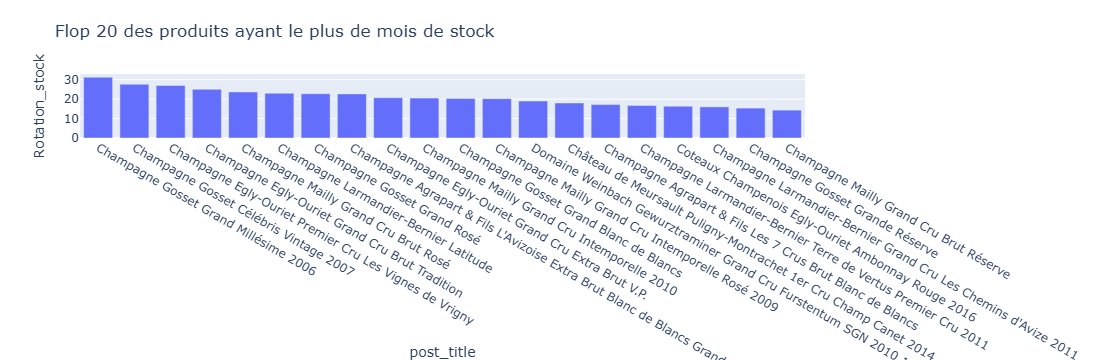

In [66]:
######################################
# Calculer le nombre de mois de stock #
######################################

# Import de la librairie NumPy
import numpy as np

# Création de la colonne Rotation de stock

# Calculer le nombre de mois pendant lesquels le stock actuel
# pourrait couvrir les ventes, à partir des ventes du mois d'octobre
df_merge_web["Rotation_stock"] = (
    df_merge_web["stock_quantity"] /
    df_merge_web["total_sales"].replace(0, np.nan)
)

# Trier les produits du plus grand au plus petit nombre de mois de stock
df_rotation_stock = df_merge_web.sort_values(
    by="Rotation_stock",
    ascending=False
)

# Afficher les 20 premières lignes pour vérifier le résultat du tri
df_rotation_stock.head(20)

# Graphique en barre du flop 20 des produits qui ont le plus de mois de stock
fig = px.bar(
    df_rotation_stock.head(20),
    x="post_title",
    y="Rotation_stock",
    title="Flop 20 des produits ayant le plus de mois de stock"
)

fig.show()

# Représenter les 20 produits ayant le plus grand nombre de mois de stock
# afin de repérer les produits dont le stock semble important par rapport aux ventes

In [67]:
# Vérifier combien de produits ont une rotation de stock non calculable
df_merge_web["Rotation_stock"].isna().sum()

np.int64(25)

In [68]:
# Compter les produits qui n'ont ni stock ni vente
# Dans ce cas, la rotation ne peut pas être calculée car les ventes sont nulles
print(
    "Produits sans stock et sans vente :",
    df_merge_web[
        (df_merge_web["stock_quantity"] == 0) &
        (df_merge_web["total_sales"] == 0)
    ].shape[0]
)

# Compter les produits qui ont encore du stock mais aucune vente
# Leur rotation est également non calculable car il n'y a pas de ventes moyennes
# permettant d'estimer le nombre de mois nécessaires pour écouler le stock
print(
    "Produits avec du stock mais aucune vente :",
    df_merge_web[
        (df_merge_web["stock_quantity"] > 0) &
        (df_merge_web["total_sales"] == 0)
    ].shape[0]
)

# Au total, 25 produits ont une rotation de stock non calculable :
# 22 produits n'ont ni stock ni vente et 3 produits ont du stock mais aucune vente.
# Ces valeurs restent donc en NaN plutôt que d'être remplacées artificiellement par 0.

Produits sans stock et sans vente : 22
Produits avec du stock mais aucune vente : 3


In [69]:
############################################
# Valorisation du stock sur l'ERP complet #
############################################

# Calculer la valeur du stock pour chaque produit de l'ERP
# en multipliant la quantité en stock par le prix d'achat
df_erp["Valorisation_stock_euros"] = (
    df_erp["stock_quantity"] * df_erp["purchase_price"]
)

# Calculer le nombre total d'unités présentes dans l'ERP
nombre_total_stock_erp = df_erp["stock_quantity"].sum()

# Calculer la valorisation totale du stock de l'ERP
valorisation_totale_stock_erp = df_erp["Valorisation_stock_euros"].sum()

# Afficher les résultats
print(
    "Nombre total d'unités dans le stock ERP :",
    nombre_total_stock_erp
)

print(
    "Valorisation totale du stock ERP :",
    round(valorisation_totale_stock_erp, 2),
    "€"
)

# Interprétation :
# Cette analyse porte sur l'ensemble des 825 produits présents dans l'ERP,
# y compris ceux qui n'ont pas pu être rapprochés d'un produit Web.
# Elle permet donc d'obtenir une vision globale du stock de l'entreprise.
#
# Les valeurs de stock négatives détectées précédemment sont conservées
# dans le calcul car aucune valeur de remplacement fiable n'est disponible.

Nombre total d'unités dans le stock ERP : 17811
Valorisation totale du stock ERP : 298555.76 €


In [70]:
###############################################
# Valorisation du stock ERP / Web apparié    #
###############################################

#Création de la colonne Valorisation des stocks en euros

# Calculer la valeur du stock pour chaque produit
# du périmètre ERP / Web apparié
# en multipliant la quantité en stock par le prix d'achat
df_merge_web["Valorisation_stock_euros"] = (
    df_merge_web["stock_quantity"] * df_merge_web["purchase_price"]
)

#Calculer la somme de la colonne "Valorisation_stock_euros"

# Calculer la valeur totale du stock sur le périmètre apparié
valorisation_totale_stock = df_merge_web["Valorisation_stock_euros"].sum()

# Afficher le résultat arrondi à 2 décimales en euros
print(
    "Valorisation du stock ERP / Web apparié :",
    round(valorisation_totale_stock, 2),
    "€"
)

# Interprétation :
# La valorisation du stock sur les 714 produits ERP / Web appariés
# est d'environ 277 305,77 €.
# Ce résultat est inférieur à la valorisation de l'ERP complet,
# car certains produits ERP ne disposent pas d'une correspondance Web exploitable.

Valorisation du stock ERP / Web apparié : 277305.77 €


In [71]:
######################################################
# Quantité totale du stock ERP / Web apparié        #
######################################################

# Calculer la somme de la colonne stock_quantity
# sur les 714 produits du périmètre ERP / Web apparié
quantite_totale_stock = df_merge_web["stock_quantity"].sum()

# Afficher le nombre total d'unités présentes en stock
print(
    "Nombre total d'unités sur le périmètre ERP / Web apparié :",
    quantite_totale_stock
)

# Interprétation :
# Les 714 produits appariés représentent au total 16 739 unités en stock.

Nombre total d'unités sur le périmètre ERP / Web apparié : 16739


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.4 - Analyse du taux de marge</h3>
</div>

In [72]:
############################
# Analyse du taux de marge #
############################

#Création de la colonne Prix HT

# Calculer le prix hors taxe à partir du prix TTC
# en retirant l'effet de la TVA à 20 %
df_merge_web["Prix_HT"] = (
    df_merge_web["price"] / 1.20
)

#Création de la colonne Prix d'achat HT

# Calculer également le prix d'achat hors taxe
# afin de comparer le prix de vente et le prix d'achat
# sur une même base hors taxes
df_merge_web["Prix_achat_HT"] = (
    df_merge_web["purchase_price"] / 1.20
)

#Création de la colonne Taux de marge

# Calculer le taux de marge de chaque produit
# en comparant la marge réalisée au prix d'achat hors taxe
df_merge_web["taux_marge"] = (
    (df_merge_web["Prix_HT"] - df_merge_web["Prix_achat_HT"])
    / df_merge_web["Prix_achat_HT"]
    * 100
)

#Afficher le taux minimum de la colonne "taux_marge"

# Rechercher le taux de marge le plus faible du catalogue
taux_marge_min = df_merge_web["taux_marge"].min()
print("Taux de marge minimum :", round(taux_marge_min, 2), "%")

#Afficher le taux maximum de la colonne "taux_marge"

# Rechercher le taux de marge le plus élevé du catalogue
taux_marge_max = df_merge_web["taux_marge"].max()
print("Taux de marge maximum :", round(taux_marge_max, 2), "%")

Taux de marge minimum : -83.67 %
Taux de marge maximum : 129.69 %


In [73]:
#Affichage de la ligne avec un taux de marge inférieur à 0

# Afficher uniquement les produits dont le taux de marge est négatif
df_merge_web[df_merge_web["taux_marge"] < 0]

# Interprétation :
# Un seul produit du périmètre ERP / Web apparié possède un taux de marge négatif.
# Son prix de vente HT est inférieur à son prix d'achat HT.
# Cette situation est atypique et doit être vérifiée avant toute correction,
# car les données disponibles ne permettent pas de savoir quelle valeur est erronée.

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,sku,total_sales,post_date,product_type,post_title,post_modified,post_type,z_score,ca_par_article,Rotation_stock,Valorisation_stock_euros,Prix_HT,Prix_achat_HT,taux_marge
201,4355,1,12.65,97,instock,77.48,12589,12589,0.0,2018-03-02 10:46:10,Champagne,Champagne Egly-Ouriet Grand Cru Blanc de Noirs,2020-08-13 10:15:02,product,-0.713272,0.0,NaN,7515.56,10.541667,64.566667,-83.673206


In [74]:
#Création d'un dataframe avec les taux positifs

# Garder uniquement les produits dont le taux de marge est supérieur à 0
df_taux_positifs = df_merge_web[df_merge_web["taux_marge"] > 0]

#Afficher le taux minimum de la colonne "taux_marge"

# Rechercher le plus petit taux de marge parmi les produits avec une marge positive
df_taux_positifs_min = df_taux_positifs["taux_marge"].min()

print("Taux de marge minimum :", round(df_taux_positifs_min, 2), "%")

#Afficher le taux maximum de la colonne "taux_marge"

# Rechercher le plus grand taux de marge parmi les produits avec une marge positive
df_taux_positifs_max = df_taux_positifs["taux_marge"].max()

print("Taux de marge maximum :", round(df_taux_positifs_max, 2), "%")

# Interprétation :
# Après avoir isolé le produit avec un taux de marge négatif,
# les taux de marge positifs du périmètre analysé
# sont compris entre 55,40 % et 129,69 %.

Taux de marge minimum : 55.4 %
Taux de marge maximum : 129.69 %


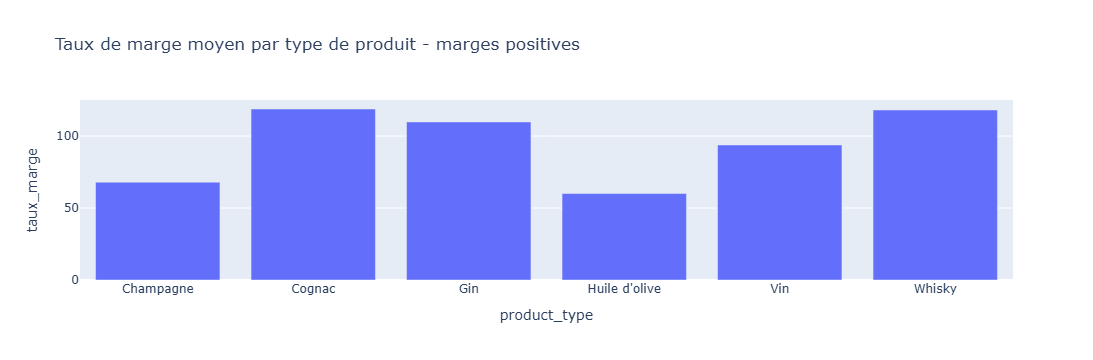

In [75]:
#Création d'un dataframe avec le taux de marge moyen par type de produit

# Regrouper les produits ayant une marge positive par catégorie
# et calculer le taux de marge moyen pour chacune d'elles
df_marge_moyenne = (
    df_taux_positifs
    .groupby("product_type")["taux_marge"]
    .mean()
)

#Affichage dans un graphique du taux de marge par type de produit

# Remettre le résultat sous forme de DataFrame
# pour pouvoir utiliser les colonnes dans le graphique
df_marge_moyenne = df_marge_moyenne.reset_index()

# Comparer visuellement le taux de marge moyen
# entre les différents types de produits
fig = px.bar(
    df_marge_moyenne,
    x="product_type",
    y="taux_marge",
    title="Taux de marge moyen par type de produit - marges positives"
)

fig.show()

# Interprétation :
# Le taux de marge moyen varie selon le type de produit.
# Le Cognac et le Whisky présentent les taux moyens les plus élevés.
# L'Huile d'olive présente le taux de marge moyen le plus faible.
# Le produit avec une marge négative a été analysé séparément
# et n'est donc pas inclus dans ces moyennes.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.5 - Analyse des corrélations entre les variables stock, sales et price</h3>
</div>

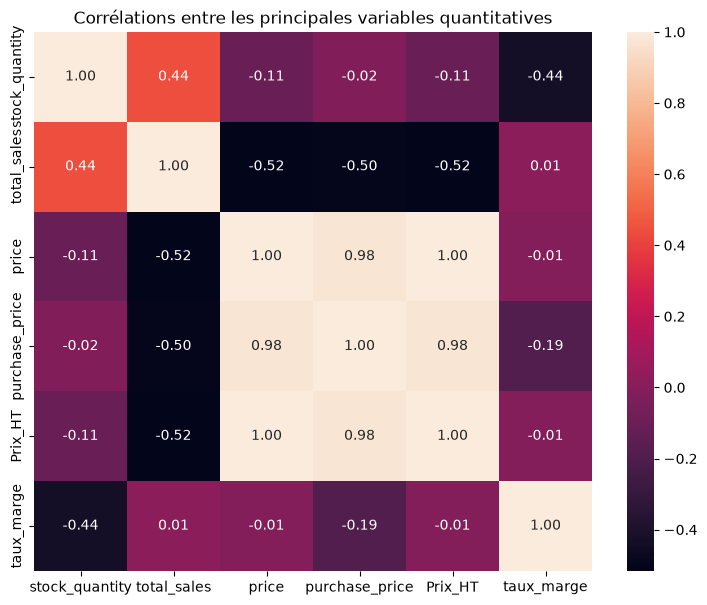

In [76]:
############################
# Analyse des corrélations #
############################

#Importation de Seaborn
import seaborn as sns

#Importation de Matplotlib
import matplotlib.pyplot as plt


#Création d'une heatmap de corrélation avec les principales variables quantitatives

# Sélectionner les variables numériques utiles pour étudier
# les relations entre le stock, les ventes, les prix et la marge
correlation = df_merge_web[[
    "stock_quantity",
    "total_sales",
    "price",
    "purchase_price",
    "Prix_HT",
    "taux_marge"
]].corr()

# Agrandir la figure pour rendre la heatmap plus lisible
plt.figure(figsize=(9, 7))

# Créer une heatmap et afficher les valeurs
# de corrélation directement dans les cases
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

# Ajouter un titre au graphique
plt.title("Corrélations entre les principales variables quantitatives")

plt.show()

In [77]:
#Que peut-on conclure des corrélations ?

# Interprétation :

# Le stock et les ventes ont une corrélation positive modérée (0,44).
# Les produits qui se vendent davantage ont donc tendance à avoir aussi plus de stock.

# Le prix et les ventes ont une corrélation négative modérée (-0,52).
# Les produits les plus chers ont donc tendance à être moins vendus.

# Le prix d'achat et les ventes ont également une corrélation négative modérée (-0,50).
# Les produits ayant un prix d'achat plus élevé ont tendance à être vendus en plus faible quantité.

# Le prix de vente et le prix d'achat sont très fortement corrélés (0,98).
# Cela montre que les produits plus chers à l'achat sont généralement aussi vendus plus cher.

# Le prix TTC et le prix HT ont une corrélation parfaite (1,00).
# Ce résultat est normal car le prix HT est directement calculé à partir du prix TTC.

# Le prix et le stock ont une corrélation très faible (-0,11).
# Il y a donc très peu de relation entre le prix d'un produit et sa quantité en stock.

# Le stock et le taux de marge présentent une corrélation négative modérée (-0,44).
# Les produits avec davantage de stock ont tendance à avoir un taux de marge plus faible.

# Le taux de marge et les ventes ont une corrélation presque nulle (0,01).
# Le niveau de marge ne semble donc pas directement lié aux quantités vendues.

# Ces corrélations montrent des tendances statistiques,
# mais elles ne prouvent pas un lien de cause à effet.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.6 - Mise à disposition de la nouvelle table sur un fichier Excel</h3>
</div>

In [78]:
#Mettre le dataset df_merge sur un fichier Excel
#Cette étape peut être utile pour partager le résultat du dataset obtenu avec les équipes.  

df_merge_web.to_excel(
    "Bottleneck_table_finale.xlsx",
    index=False
)